# Laboratory Exercise: Image Classification Using Pre-trained Models
**Task:** classify stock candlestick chart images into 3 classes (0, 1, 2) by fine-tuning five pre-trained `torchvision` models and comparing accuracy, precision, recall and F1-score.

In [1]:
import gc
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

C:\Users\User\anaconda3\envs\notebook\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.stats import gaussian_kde


cuda


## 1. Dataset
Folder layout: `STOCK_CANDLES/<class>/<image>`, where the folder name (0, 1, 2) is the label.

> **Curation notes (replace):** source = ..., images per class = ..., what each class means = ...

In [2]:
root = 'STOCK_CANDLES'

# Rename these to what your classes actually mean, in label order 0, 1, 2
class_names = ['0', '1', '2']

data_dict = {'X': [], 'y': []}
for cls in os.listdir(root):
    cls_path = os.path.join(root, cls)
    for img in os.listdir(cls_path):
        data_dict['X'].append(os.path.join(cls_path, img))
        data_dict['y'].append(int(cls))

df = pd.DataFrame(data_dict)
print(len(df), "images")
df['y'].value_counts().sort_index()

249 images


y
0    81
1    94
2    74
Name: count, dtype: int64

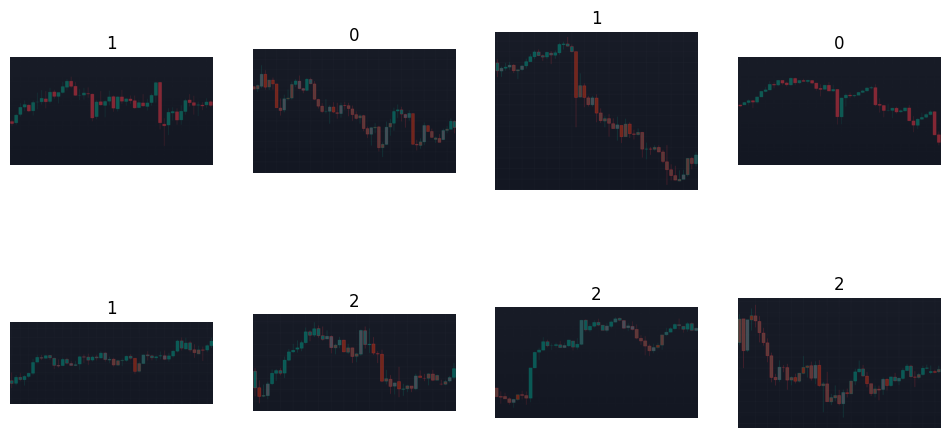

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.ravel(), df.sample(8, random_state=42).iterrows()):
    ax.imshow(Image.open(row["X"]).convert("RGB"))
    ax.set_title(class_names[row['y']])
    ax.axis("off")
plt.show()

## 2. Custom `Dataset` and `DataLoader`
All models use the same preprocessing: resize the **whole** chart to 224x224 and normalize with ImageNet statistics. I do not use each model's default `weights.transforms()` because it center-crops, which would cut off the left and right ends of a wide chart. There is no horizontal-flip augmentation either, because flipping a chart reverses time and would turn an uptrend into a downtrend.

In [4]:
tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class CustomDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transforms=None):
        self.X = df['X'].to_list()
        self.labels = df['y'].to_list()
        self.transforms = transforms

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        img = Image.open(self.X[idx]).convert("RGB")   # force 3-channel RGB
        if self.transforms is not None:
            img = self.transforms(img)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, label

x, y = CustomDataset(df, tf)[0]
print(len(df), x.shape, y)

249 torch.Size([3, 224, 224]) tensor(0)


## 3. Models, training and evaluation
The 1000-class ImageNet layer of each model is replaced with a new 3-class layer, then the model is trained on the training split (70%) and scored on the unseen test split (30%). `FREEZE_BACKBONE = True` trains only the new layer; set it to `False` to fine-tune the whole network (slower, needs a smaller learning rate).

In [5]:
SEED = 42
EPOCHS = 5
FREEZE_BACKBONE = True
LR = 1e-3 if FREEZE_BACKBONE else 1e-4
BATCH_SIZE = 16
NUM_CLASSES = 3

train_df, test_df = train_test_split(df, test_size=0.3, stratify=df["y"], random_state=SEED)
print(len(train_df), "train /", len(test_df), "test")

MODEL_CONFIGS = {
    "MobileNetV3-Large": (models.mobilenet_v3_large, models.MobileNet_V3_Large_Weights.DEFAULT),
    "EfficientNet-B0":   (models.efficientnet_b0,    models.EfficientNet_B0_Weights.DEFAULT),
    "ResNet-50":         (models.resnet50,           models.ResNet50_Weights.DEFAULT),
    "VGG-16":            (models.vgg16,              models.VGG16_Weights.DEFAULT),
    "ViT-B/16":          (models.vit_b_16,           models.ViT_B_16_Weights.DEFAULT),
}

def replace_head(model, name, n):
    if name == "ResNet-50":
        model.fc = nn.Linear(model.fc.in_features, n)
    elif name == "ViT-B/16":
        model.heads.head = nn.Linear(model.heads.head.in_features, n)
    elif name == "MobileNetV3-Large":
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, n)
    elif name == "EfficientNet-B0":
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, n)
    elif name == "VGG-16":
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, n)
    return model

def train(model, loader):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()
    for ep in range(EPOCHS):
        model.train(not FREEZE_BACKBONE)   # frozen layers stay in eval mode (BatchNorm/dropout unchanged)
        total = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            total += loss.item() * len(y)
        print(f"epoch {ep+1}/{EPOCHS}  loss {total/len(loader.dataset):.4f}")

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for x, y in loader:
        y_pred += model(x.to(device)).argmax(dim=1).cpu().tolist()
        y_true += y.tolist()
    return np.array(y_true), np.array(y_pred)

174 train / 75 test


In [6]:
train_loader = DataLoader(CustomDataset(train_df, tf), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(CustomDataset(test_df, tf), batch_size=BATCH_SIZE, shuffle=False)

results, confusions = [], {}

for name, (builder, weights) in MODEL_CONFIGS.items():
    print(f"Fine-tuning {name} ...")
    torch.manual_seed(SEED)

    model = builder(weights=weights)
    if FREEZE_BACKBONE:
        for p in model.parameters():
            p.requires_grad = False
    model = replace_head(model, name, NUM_CLASSES)   # new layer is trainable by default
    n_params = sum(p.numel() for p in model.parameters()) / 1e6

    train(model, train_loader)
    y_true, y_pred = evaluate(model, test_loader)

    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    results.append({"Model": name, "Params (M)": n_params,
                    "Accuracy": accuracy_score(y_true, y_pred),
                    "Precision": prec, "Recall": rec, "F1-score": f1})
    confusions[name] = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))

    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(3)

Fine-tuning MobileNetV3-Large ...
epoch 1/5  loss 1.1231
epoch 2/5  loss 1.0565
epoch 3/5  loss 1.0513
epoch 4/5  loss 1.0144
epoch 5/5  loss 0.9876
Fine-tuning EfficientNet-B0 ...
epoch 1/5  loss 1.1523
epoch 2/5  loss 1.1191
epoch 3/5  loss 1.0781
epoch 4/5  loss 1.0536
epoch 5/5  loss 1.0473
Fine-tuning ResNet-50 ...
epoch 1/5  loss 1.1124
epoch 2/5  loss 1.0716
epoch 3/5  loss 1.0577
epoch 4/5  loss 1.0427
epoch 5/5  loss 1.0275
Fine-tuning VGG-16 ...
epoch 1/5  loss 1.2926
epoch 2/5  loss 1.0977
epoch 3/5  loss 0.9905
epoch 4/5  loss 0.9302
epoch 5/5  loss 0.8793
Fine-tuning ViT-B/16 ...
epoch 1/5  loss 1.1390
epoch 2/5  loss 1.1229
epoch 3/5  loss 1.0755
epoch 4/5  loss 1.0558
epoch 5/5  loss 1.0159


,Params (M),Accuracy,Precision,Recall,F1-score
Model,,,,,
MobileNetV3-Large,4.206,0.453,0.446,0.447,0.444
EfficientNet-B0,4.011,0.427,0.427,0.428,0.415
ResNet-50,23.514,0.467,0.506,0.449,0.436
VGG-16,134.273,0.440,0.423,0.421,0.405
ViT-B/16,85.801,0.347,0.309,0.329,0.288


## 4. Results

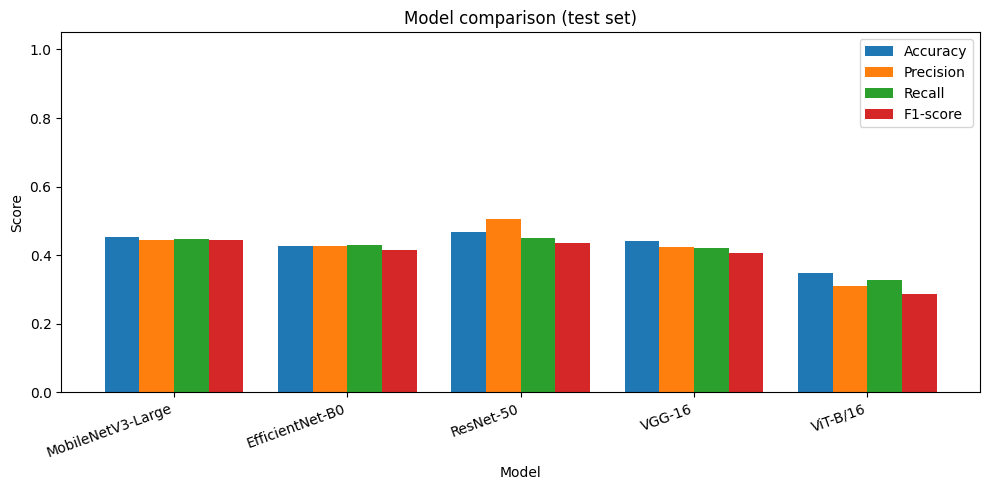

In [7]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
ax = results_df[metrics].plot(kind="bar", figsize=(10, 5), width=0.8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Model comparison (test set)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

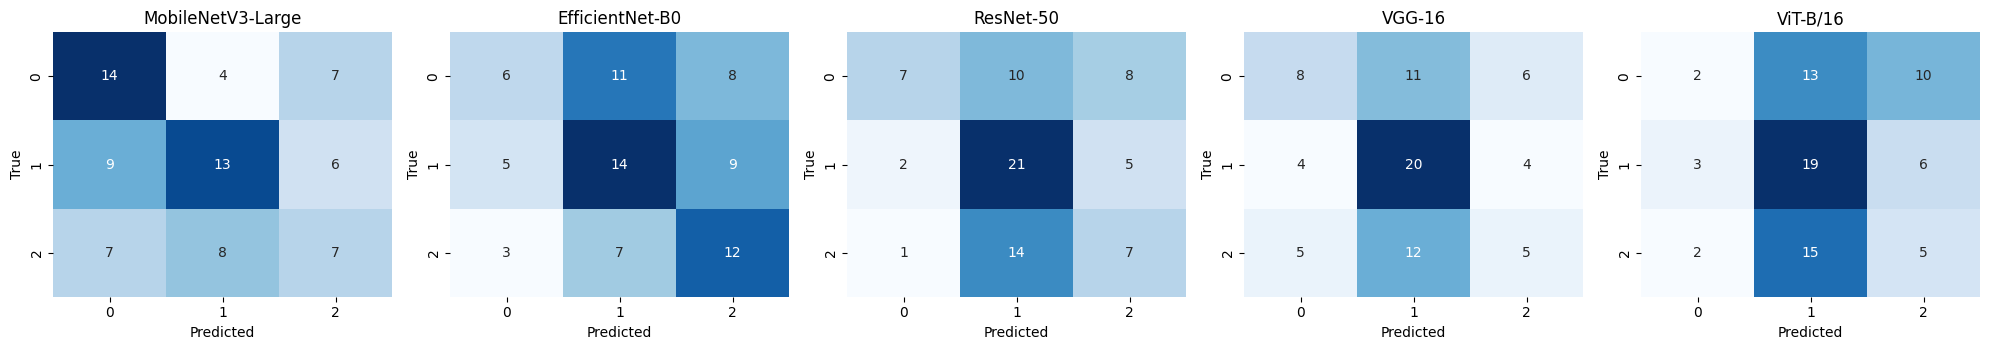

In [8]:
fig, axes = plt.subplots(1, len(confusions), figsize=(4 * len(confusions), 3.6))
for ax, (name, cm) in zip(axes, confusions.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

## 5. Analysis and conclusion
> Fill this in after running the notebook, using your own numbers.

**Results.** Which model scored highest and lowest (accuracy and F1)? How big is the gap? The test set has only ~75 images, so one wrong image moves accuracy by about 1.3 points; say whether the gaps are large enough to matter. Which classes were confused most (confusion matrices)?

**Why the models differ.** Tie each point to your table:
- *Architecture:* residual connections (ResNet-50), depthwise-separable convolutions (MobileNetV3), compound scaling (EfficientNet-B0), plain stacked convolutions (VGG-16), patch-based self-attention (ViT-B/16).
- *Complexity:* compare `Params (M)` with the scores. Did bigger models do better?
- *Input requirements:* all models received the same 224x224 normalized input. Explain why the whole chart was resized instead of cropped, and why flipping was not used.
- *Suitability for the dataset:* the models were pre-trained on natural photos (ImageNet), but candlestick charts are synthetic images made of thin bars on a dark background. Discuss how this mismatch, and training only the final layer, may limit accuracy, and why texture/edge features from ImageNet may or may not transfer.
- *Small dataset:* 174 training images per model; discuss overfitting and the variance of the results.

**Conclusion.** Which model would you choose and why (accuracy vs. size)? What would you try next (more data, `FREEZE_BACKBONE = False`, more epochs, a repeated or cross-validated split)?